# Estimate the slot A effect

The three compounds of every validation plate rotate through the 24 compound wells in the same pattern on every plate, so a well position always holds the compound of one **slot** (A, B, or C).
The compounds were dispensed into the slots at random, and the compounds of slot A score lower than those of slots B and C on all five plates (see the [README](./README.md)).
The position correction (`../4a.position_correction/`) is a row plus column tilt, and each compound sits in the wells of one slot only, so a slot effect cannot be told from the effect of the compound on a plate and the tilt does not remove it.

This notebook estimates the slot A effect and how much of the estimate to trust:

1. **The estimate.** For every plate, the profile of each compound is the mean of the position-corrected medians of its 8 wells. The slot A effect of a plate is the profile of the compound in slot A minus the mean of the other two, and the estimate is the mean over the five plates (one number for every feature).
2. **The chance part.** The five compounds of slot A also differ from the others by chance. We permute which compound of each plate is the one in slot A (3 ** 5 = 243 arrangements, one of which is the real one) and compute the mean squared size of the estimate, its *energy*, for each.
3. **The shrinkage factor** is the share of the observed energy that the median arrangement does not give: `(energy - median of the arrangements) / energy`. The adjustment of `1.apply_slot_a_adjustment.ipynb` subtracts this share of the estimate.

**Input** (from `../4a.position_correction/`): `position_correction_fit.npz` and the cache of the well medians `well_medians.parquet`.

**Output**
- `slot_a_adjustment.npz`: the estimate (one value for every feature), the shrinkage factor, and what they come from. Step `1.apply_slot_a_adjustment.ipynb` reads it.
- `figures/slot_a_null.png`, `figures/slot_a_vector_by_family.png`, and `figures/compound_profiles_before_after.png`.
The notebook prints the tables (the permutation null, the estimate by feature family, and the estimate without each plate).

In [1]:
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

sys.path.append("../../../utils")
import position_correction_utils as pcu
import slot_adjustment_utils as sau
import validation_position_utils as vpu

position_dir = pathlib.Path("../4a.position_correction")
figure_dir = pathlib.Path("figures")
figure_dir.mkdir(exist_ok=True)

min_cells = 50  # minimum cells of a well, as in the position correction
slot_colors = {"A": "#d95f02", "B": "#7570b3", "C": "#1b9e77"}

## Well medians and the position correction

The well medians are the cache that `../4a.position_correction/1.fit_position_correction.ipynb` writes (git ignores it), and the compound profiles below are corrected with the committed fit like the profiles of step 4b.

In [2]:
well_medians, features = vpu.load_or_build_well_medians(
    position_dir / "well_medians.parquet", ".", platemap_dir="../../metadata/platemaps", rebuild=False
)
fit = vpu.load_validation_fit(position_dir / "position_correction_fit.npz")
print("Well medians:", well_medians.shape, "| features of the fit:", len(fit["features"]))
print("Slot A wells:", sau.SLOT_WELLS["A"])

Well medians: (300, 2459) | features of the fit: 2453
Slot A wells: ('B05', 'B08', 'C07', 'D06', 'E05', 'E08', 'F06', 'G07')


/var/folders/02/q30k_4wn2dqbz5pj_vvc8xn40000gp/T/ipykernel_23977/721897820.py:1: UserWarning: Using the cached well medians in ../4a.position_correction/well_medians.parquet, which were written on 2026-11-24 14:30. They are not checked against the single-cell profiles. Set REBUILD_WELL_MEDIANS=1 (or pass rebuild=True) to build them again from the profiles.
  well_medians, features = vpu.load_or_build_well_medians(


## The compounds in the slots

Every compound has its wells in one slot, and every plate has one compound in each slot (`compound_slot_table` stops otherwise).

In [3]:
adjustment = sau.estimate_slot_a_adjustment(well_medians, fit, min_cells=min_cells)
compounds = adjustment["compounds"].pivot(index="plate", columns="slot", values="treatment")
print(compounds.to_string())

slot                             A     B     C
plate                                         
CARD-CelIns-CX7_261030160001  K310  K543  K278
CARD-CelIns-CX7_261031160001  K756  K020  K845
CARD-CelIns-CX7_261101160003  K463  K208  K779
CARD-CelIns-CX7_261102080001  K221  K318  K645
CARD-CelIns-CX7_261102150001  K504  K687  K191


## The estimate and its permutation null

In [4]:
print(f"Features: {len(adjustment['features'])}")
print(f"Energy of the estimate (mean squared size per feature): {adjustment['energy']:.4f} (RMS {np.sqrt(adjustment['energy']):.3f})")
null = adjustment["null_energies"]
print(
    f"Arrangements: {len(null)}; median {adjustment['null_median']:.4f} (RMS {np.sqrt(adjustment['null_median']):.3f}), "
    f"95th percentile {np.percentile(null, 95):.4f}"
)
print(f"Share of the arrangements with an energy at least as large (p-value): {adjustment['p_value']:.4f}")
print(f"Shrinkage factor (energy - median) / energy: {adjustment['factor']:.3f}")
sau.save_slot_adjustment(adjustment, "slot_a_adjustment.npz")

families = pd.DataFrame([vpu.parse_feature_family(name) for name in adjustment["features"]])
by_feature = pd.concat(
    [
        pd.DataFrame(
            {
                "feature": adjustment["features"],
                "vector": adjustment["vector"],
                "shrunk_vector": adjustment["factor"] * adjustment["vector"],
            }
        ),
        families,
    ],
    axis=1,
)


Features: 2453
Energy of the estimate (mean squared size per feature): 0.0741 (RMS 0.272)
Arrangements: 243; median 0.0292 (RMS 0.171), 95th percentile 0.0679
Share of the arrangements with an energy at least as large (p-value): 0.0412
Shrinkage factor (energy - median) / energy: 0.606


## Without each plate in turn

The estimate has only five plates, so we also make it without each plate in turn (four plates, 3 ** 4 = 81 arrangements).
The five estimates show how much the slot A vector and its shrinkage factor depend on a single plate, and the hit calling uses them to carry the uncertainty of the estimate into the scores.

In [5]:
full = adjustment["vector"]
jackknife = pd.DataFrame(
    {
        "left_out_plate": adjustment["plates"],
        "energy": adjustment["jackknife_energies"],
        "p_value": adjustment["jackknife_p_values"],
        "factor": adjustment["jackknife_factors"],
        "cosine_to_full_estimate": [
            float(v @ full / np.linalg.norm(v) / np.linalg.norm(full)) for v in adjustment["jackknife_vectors"]
        ],
    }
)
print(jackknife.round(3).to_string(index=False))

              left_out_plate  energy  p_value  factor  cosine_to_full_estimate
CARD-CelIns-CX7_261030160001   0.076    0.099   0.500                    0.984
CARD-CelIns-CX7_261031160001   0.077    0.123   0.453                    0.977
CARD-CelIns-CX7_261101160003   0.069    0.123   0.497                    0.980
CARD-CelIns-CX7_261102080001   0.082    0.099   0.509                    0.995
CARD-CelIns-CX7_261102150001   0.082    0.025   0.659                    0.959


## Figure: the estimate against random assignment

Each bar is the energy of an arrangement of the compounds in the slots (243 in all).
The real arrangement has a larger energy than 95.9% of them, and the part of it above the median arrangement is the share that we subtract.

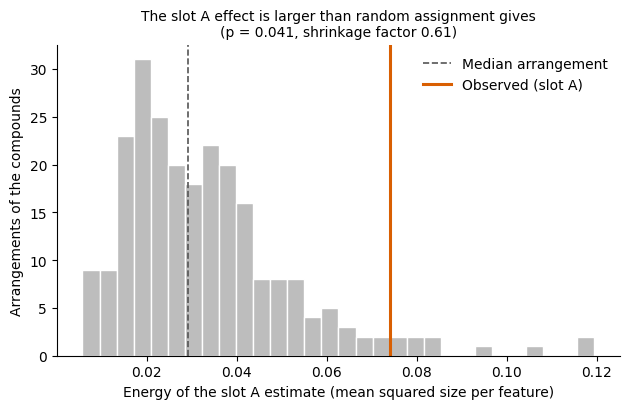

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.hist(null, bins=30, color="#bdbdbd", edgecolor="white")
ax.axvline(adjustment["null_median"], color="#555555", ls="--", lw=1.2, label="Median arrangement")
ax.axvline(adjustment["energy"], color=slot_colors["A"], lw=2.2, label="Observed (slot A)")
ax.set_xlabel("Energy of the slot A estimate (mean squared size per feature)")
ax.set_ylabel("Arrangements of the compounds")
ax.legend(frameon=False)
ax.set_title(
    f"The slot A effect is larger than random assignment gives\n(p = {adjustment['p_value']:.3f}, shrinkage factor {adjustment['factor']:.2f})",
    fontsize=10,
)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(figure_dir / "slot_a_null.png", dpi=150)
plt.show()

## Figure: which features carry the slot A effect

The size (root mean square over the features) of the estimate, by channel and by measurement type, next to the size of the position tilt (`../4a.position_correction/`, Figure 3 of the supplementary details).

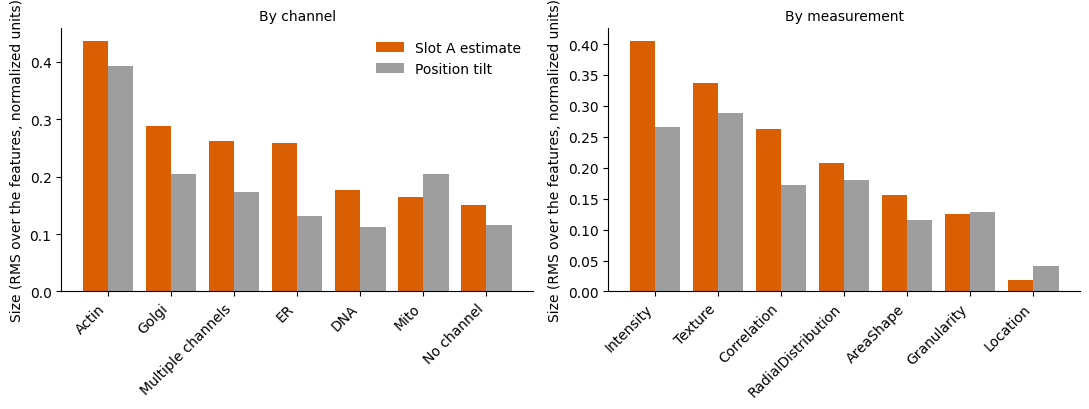

In [7]:
tilt = vpu.tilt_size_by_feature(fit).set_index("feature")
by_feature["tilt_rms"] = by_feature["feature"].map(tilt["tilt_rms"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, key in zip(axes, ("channel", "measurement")):
    summary = by_feature.groupby(key).agg(
        slot=("vector", lambda v: float(np.sqrt((v**2).mean()))),
        tilt=("tilt_rms", lambda v: float(np.sqrt((v**2).mean()))),
        n=("vector", "size"),
    )
    summary = summary[summary["n"] >= 20].sort_values("slot", ascending=False)
    x = np.arange(len(summary))
    ax.bar(x - 0.2, summary["slot"], 0.4, color=slot_colors["A"], label="Slot A estimate")
    ax.bar(x + 0.2, summary["tilt"], 0.4, color="#9e9e9e", label="Position tilt")
    ax.set_xticks(x)
    ax.set_xticklabels(summary.index, rotation=45, ha="right")
    ax.set_ylabel("Size (RMS over the features, normalized units)")
    ax.set_title(f"By {key}", fontsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(figure_dir / "slot_a_vector_by_family.png", dpi=150)
plt.show()

## Figure: the 15 compound profiles before and after the adjustment

The profile of every compound (the mean of its 8 position-corrected wells) in the first two principal components of the 15 compounds, colored by slot.
After the adjustment the compounds of slot A move by the shrunk estimate.

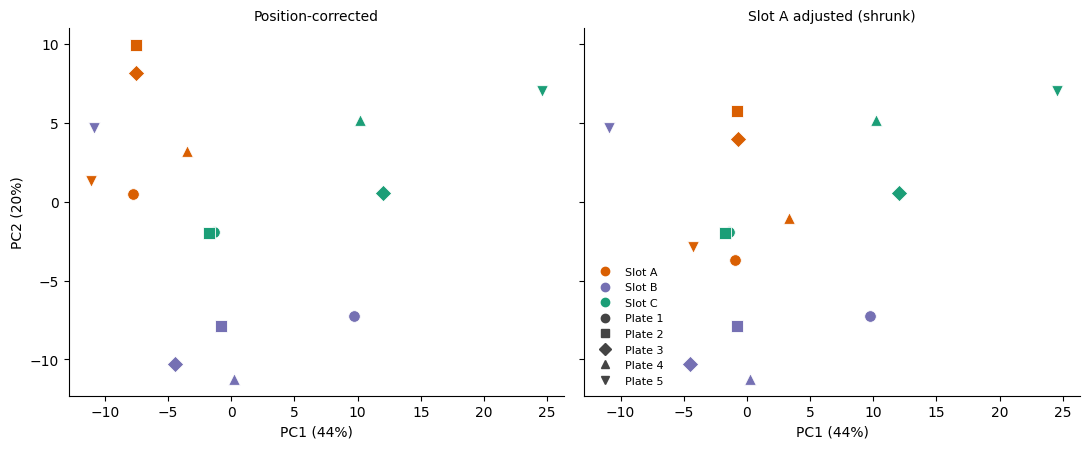

In [8]:
table = sau.compound_slot_table(well_medians, fit, adjustment["features"], min_cells)
values = table[adjustment["features"]].to_numpy(float)
shifted = values.copy()
is_a = (table["slot"] == "A").to_numpy()
shifted[is_a] -= adjustment["factor"] * adjustment["vector"]
pca = PCA(n_components=2, random_state=0).fit(values)
markers = dict(zip(sorted(table["plate"].unique()), "osD^v"))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, data, title in zip(axes, (values, shifted), ("Position-corrected", "Slot A adjusted (shrunk)")):
    scores = pca.transform(data)
    for (plate, slot), x in zip(zip(table["plate"], table["slot"]), scores):
        ax.scatter(x[0], x[1], s=70, color=slot_colors[slot], marker=markers[plate], edgecolor="white", lw=0.6)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(f"PC1 ({100 * pca.explained_variance_ratio_[0]:.0f}%)")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.0f}%)")
handles = [plt.Line2D([], [], marker="o", ls="", color=color, label=f"Slot {slot}") for slot, color in slot_colors.items()]
handles += [plt.Line2D([], [], marker=m, ls="", color="#444444", label=f"Plate {i + 1}") for i, m in enumerate(markers.values())]
axes[1].legend(handles=handles, frameon=False, fontsize=8, loc="best")
fig.tight_layout()
fig.savefig(figure_dir / "compound_profiles_before_after.png", dpi=150)
plt.show()